[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-biopython-course/blob/main/notebooks/04_sequence_features_annotations.ipynb)

# 04 · Sequence Features and Annotations

*Practical Biopython Course · Hamza Hentabli, Ph.D. · ~50 min*

A GenBank record is a sequence plus a list of **features**: genes, exons, coding sequences,
signal peptides, modification sites. Reading them programmatically is how you go from "a sequence"
to "where is the kinase domain, and which exon carries the resistance mutation?". We use the human
EGFR mRNA record `NM_005228.5` (NCBI RefSeq, cached in `data/entrez_cache/`).

**Learning objectives.** By the end of this notebook you will be able to:

- list and filter the features of a GenBank record
- read feature locations and qualifiers, and extract a CDS with `feature.extract`
- map between mRNA (nucleotide) and protein (residue) coordinates
- locate clinically important mutations in exons, and draw a simple feature map

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Install requirements.txt once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'biopython'], check=True)
    if not os.path.isdir("practical-biopython-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-biopython-course.git"], check=True)
    DATA_DIR = "practical-biopython-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


## 1. What features does the record have?

In [2]:
from collections import Counter
from Bio import SeqIO
from Bio.Seq import Seq
from Bio.SeqFeature import SeqFeature, FeatureLocation
import pandas as pd
import matplotlib.pyplot as plt

gb = SeqIO.read(f"{DATA_DIR}/entrez_cache/NM_005228.gb", "genbank")
print(gb.id, len(gb), "nt")
Counter(f.type for f in gb.features)

NM_005228.5 9905 nt


Counter({'misc_feature': 44,
         'exon': 28,
         'regulatory': 3,
         'polyA_site': 3,
         'source': 1,
         'gene': 1,
         'CDS': 1,
         'sig_peptide': 1,
         'mat_peptide': 1})

In [3]:
source = gb.features[0]
print(source.type, source.location)
for key, value in source.qualifiers.items():
    print(f"  {key}: {value}")

source [0:9905](+)
  organism: ['Homo sapiens']
  mol_type: ['mRNA']
  db_xref: ['taxon:9606']
  chromosome: ['7']
  map: ['7p11.2']


Each feature has a `type`, a `location` (zero-based, end-exclusive, with a strand) and a dictionary
of `qualifiers` whose values are **lists** of strings.

## 2. The coding sequence (CDS)

In [4]:
cds = next(f for f in gb.features if f.type == "CDS")
print("location:", cds.location, "| strand:", cds.location.strand)
for key in ["gene", "product", "protein_id", "codon_start", "EC_number"]:
    print(f"{key:>11}: {cds.qualifiers.get(key)}")
print("db_xref:", cds.qualifiers["db_xref"])

location: [261:3894](+) | strand: 1
       gene: ['EGFR']
    product: ['epidermal growth factor receptor isoform a precursor']
 protein_id: ['NP_005219.2']
codon_start: ['1']
  EC_number: ['2.7.10.1']
db_xref: ['CCDS:CCDS5514.1', 'GeneID:1956', 'HGNC:HGNC:3236', 'MIM:131550']


In [5]:
cds_seq = cds.extract(gb.seq)          # handles strand and multi-part (join) locations for you
protein = cds_seq.translate(to_stop=True)
print(len(cds_seq), "nt ->", len(protein), "aa")
print("matches the annotated translation:", str(protein) == cds.qualifiers["translation"][0])

3633 nt -> 1210 aa
matches the annotated translation: True


Always use `feature.extract(record.seq)` instead of manual slicing: for minus-strand or spliced
(`join(...)`) features it does the reverse complement and concatenation correctly.

## 3. Exons

In [6]:
exons = [f for f in gb.features if f.type == "exon"]
exon_table = pd.DataFrame({
    "exon": range(1, len(exons) + 1),
    "start": [int(f.location.start) + 1 for f in exons],    # 1-based for humans
    "end": [int(f.location.end) for f in exons],
})
exon_table["length"] = exon_table["end"] - exon_table["start"] + 1
print(len(exons), "exons")
exon_table.head(8)

28 exons


,exon,start,end,length
0,1,1,349,349
1,2,350,501,152
2,3,502,685,184
3,4,686,820,135
4,5,821,889,69
5,6,890,1008,119
6,7,1009,1150,142
7,8,1151,1267,117


## 4. From residue number to nucleotide, codon, and exon

The CDS starts at zero-based position `cds.location.start`. Residue *n* is encoded by the three
nucleotides starting at `cds_start + 3*(n-1)`. Let us locate three mutations that decide which EGFR
inhibitor a lung-cancer patient receives.

In [7]:
cds_start = int(cds.location.start)

def residue_info(n):
    nt = cds_start + 3 * (n - 1)
    exon = next(i + 1 for i, f in enumerate(exons) if nt in f.location)
    codon = gb.seq[nt: nt + 3]
    return {"residue": f"{codon.translate()}{n}", "mRNA position (1-based)": nt + 1,
            "codon": str(codon), "exon": exon}

pd.DataFrame([residue_info(n) for n in (746, 790, 797, 858)])

,residue,mRNA position (1-based),codon,exon
0,E746,2497,GAA,19
1,T790,2629,ACG,20
2,C797,2650,TGC,20
3,L858,2833,CTG,21


- **Exon 19 deletions** (around E746–A750) and **L858R** (exon 21) are activating mutations that make
  tumours sensitive to gefitinib and erlotinib.
- **T790M** (exon 20) is the "gatekeeper" resistance mutation that motivated third-generation inhibitors
  such as osimertinib, which binds covalently to **C797**.

These positions are now just rows in a table you computed from the GenBank file.

## 5. Annotated sites: modifications and regions

In [8]:
def to_residue(f):
    return (int(f.location.start) - cds_start) // 3 + 1

sites = [(to_residue(f), f.qualifiers["note"][0].split(".")[0].split(";")[0])
         for f in gb.features if f.type == "misc_feature"]
sites_df = pd.DataFrame(sites, columns=["residue", "annotation"])
sites_df["kind"] = sites_df["annotation"].str.extract(r"^(Phospho\w+|N-linked|Region|propagated)")[0]
sites_df["kind"].value_counts()

kind
N-linked            13
Phosphoserine       12
Phosphotyrosine      8
propagated           5
Phosphothreonine     3
Name: count, dtype: int64

In [9]:
tyr = sites_df[sites_df["annotation"].str.startswith("Phosphotyrosine")]
print("phosphotyrosines:", tyr["residue"].tolist())

phosphotyrosines: [869, 998, 1016, 1069, 1092, 1110, 1172, 1197]


## 6. Creating your own feature

GenBank does not annotate the kinase domain, but UniProt does (residues 712–979). We add it as a new
feature in mRNA coordinates and check that extracting it gives the right protein.

In [10]:
kd_start, kd_end = 712, 979
kinase_feature = SeqFeature(FeatureLocation(cds_start + 3 * (kd_start - 1), cds_start + 3 * kd_end, strand=1),
                            type="misc_feature", qualifiers={"note": ["protein kinase domain (UniProt P00533)"]})
gb.features.append(kinase_feature)
kd_protein = kinase_feature.extract(gb.seq).translate()
print(kinase_feature.location, len(kd_protein), "aa:", kd_protein[:20], "...", kd_protein[-10:])

[2394:3198](+) 268 aa: FKKIKVLGSGAFGTVYKGLW ... KMARDPQRYL


## 7. A feature map

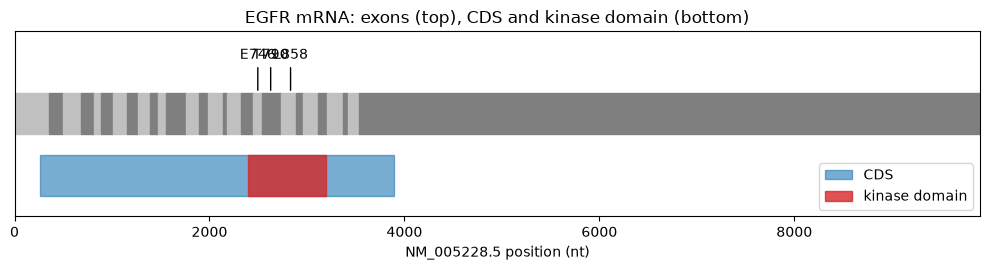

In [11]:
fig, ax = plt.subplots(figsize=(10, 2.8))
for i, f in enumerate(exons):
    ax.add_patch(plt.Rectangle((int(f.location.start), 0.6), len(f), 0.3,
                               color="tab:gray" if i % 2 else "silver"))
ax.add_patch(plt.Rectangle((int(cds.location.start), 0.15), len(cds), 0.3, color="tab:blue", alpha=0.6, label="CDS"))
ax.add_patch(plt.Rectangle((int(kinase_feature.location.start), 0.15), len(kinase_feature), 0.3,
                           color="tab:red", alpha=0.8, label="kinase domain"))
for n in (746, 790, 858):
    x = cds_start + 3 * (n - 1)
    ax.annotate(residue_info(n)["residue"], (x, 0.9), (x, 1.15), ha="center",
                arrowprops=dict(arrowstyle="-", color="k"))
ax.set_xlim(0, len(gb)); ax.set_ylim(0, 1.35); ax.set_yticks([])
ax.set_xlabel("NM_005228.5 position (nt)"); ax.legend(loc="lower right")
ax.set_title("EGFR mRNA: exons (top), CDS and kinase domain (bottom)")
plt.tight_layout(); plt.show()

### ✏️ Exercise 1

Which exon contains the most annotated **N-linked glycosylation** sites? Use `sites_df` and the exon
locations.

In [12]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
nlinked = [f for f in gb.features if f.type == "misc_feature" and f.qualifiers["note"][0].startswith("N-linked")]
counts = Counter(next(i + 1 for i, e in enumerate(exons) if int(f.location.start) in e.location) for f in nlinked)
print(counts.most_common(3))
```

</details>

### ✏️ Exercise 2

Extract the **signal peptide** (`sig_peptide` feature) and translate it. How many residues long is it,
and is it hydrophobic (count L, A, V, I residues)?

In [13]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
sig = next(f for f in gb.features if f.type == "sig_peptide")
pep = sig.extract(gb.seq).translate()
print(pep, len(pep), "aa | L/A/V/I:", sum(pep.count(a) for a in "LAVI"))
```

</details>

### ✏️ Exercise 3

How many of the 28 exons lie (at least partly) inside the kinase domain feature you created?

In [14]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
inside = [i + 1 for i, e in enumerate(exons)
          if e.location.start < kinase_feature.location.end and e.location.end > kinase_feature.location.start]
print(len(inside), "exons:", inside)
```

</details>

## Key takeaways

- `record.features` is a list of `SeqFeature`s with `type`, `location`, and `qualifiers`.
- `feature.extract(seq)` is the safe way to get a feature's sequence.
- Residue *n* → nucleotide `cds_start + 3(n−1)`: this simple mapping locates clinical mutations in exons.

**Next:** [05 · NCBI Entrez](05_ncbi_entrez.ipynb).